In [53]:
import math
import re
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, roc_curve, roc_auc_score

import pickle

#Loading the dataset
!wget -q -O cardiovascular_dataset.zip \
"https://www.kaggle.com/api/v1/datasets/download/sulianova/cardiovascular-disease-dataset"

import zipfile

with zipfile.ZipFile(
    "cardiovascular_dataset.zip",
    "r"
) as zip_ref:

    zip_ref.extractall("cardiovascular_data")

df = pd.read_csv(
    "cardiovascular_data/cardio_train.csv",
    sep=";"
)

list(df.columns)

['id',
 'age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

In [54]:
pd.concat([df.head(5), df.sample(5), df.tail(5)])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0
27052,38676,22004,1,172,63.0,110,70,2,1,0,0,1,0
26599,37999,22641,2,162,92.0,120,80,1,1,0,0,1,1
58287,83168,19688,1,164,63.0,130,80,1,1,0,0,1,1
6119,8703,19712,1,169,67.0,120,80,1,1,0,0,1,0
36189,51676,16610,2,165,63.0,150,80,1,1,0,0,1,1


In [55]:
df.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


# **Preprocessing**

unique values

In [57]:
pd.DataFrame([ df.nunique(), df.dtypes ], index=['Unique Values', 'Data Types'])

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
Unique Values,70000,8076,2,109,287,153,157,3,3,2,2,2,2
Data Types,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,int64,int64


In [58]:
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [59]:
TARGET = 'cardio'

INPUT_FEATURES = [
    'id', 'age', 'gender', 'height', 'weight',
    'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

# Check the dataset
pd.DataFrame(
    [df.nunique(), df.dtypes],
    index=['Unique Values', 'Data Types']
)

# Check for duplicate rows
duplicates = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicates}")

# Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Dataset shape after removing duplicates: {df.shape}")

# Check for missing values
pd.DataFrame(
    {
        "Count": df.isna().sum().sort_values(ascending=False),
        "percent %": 100.0 * df.isna().sum().sort_values(ascending=False) / len(df),
    }
).T

# Check categorical values for consistency
for col in ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())

# Function for removing unwanted features
def drop_unwanted_features(df, feature_to_drop):
    print(f"\nDropping feature: {feature_to_drop}")

    if feature_to_drop in df.columns:
        df = df.drop(columns=[feature_to_drop])

    if feature_to_drop in INPUT_FEATURES:
        INPUT_FEATURES.remove(feature_to_drop)

    return df

# Remove ID because it is an identifier, not a predictive feature
df = drop_unwanted_features(df, 'id')

Number of duplicate rows: 0
Dataset shape after removing duplicates: (70000, 13)

gender
gender
1    45530
2    24470
Name: count, dtype: int64

cholesterol
cholesterol
1    52385
2     9549
3     8066
Name: count, dtype: int64

gluc
gluc
1    59479
2     5190
3     5331
Name: count, dtype: int64

smoke
smoke
0    63831
1     6169
Name: count, dtype: int64

alco
alco
0    66236
1     3764
Name: count, dtype: int64

active
active
0    13739
1    56261
Name: count, dtype: int64

cardio
cardio
0    35021
1    34979
Name: count, dtype: int64

Dropping feature: id


In [60]:
# Check blood pressure consistency

invalid_bp = df['ap_lo'] >= df['ap_hi']

print(
    f"Records where diastolic BP >= systolic BP: "
    f"{invalid_bp.sum()}"
)

# Remove invalid BP records
df = df[df['ap_lo'] < df['ap_hi']].copy()

print(f"Dataset shape after BP cleaning: {df.shape}")

Records where diastolic BP >= systolic BP: 1236
Dataset shape after BP cleaning: (68764, 12)


In [61]:
list(df.columns)

['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'cardio']

Outliers

In [62]:
def find_iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return (series < lower) | (series > upper)


outlier_features = ['age', 'height', 'weight', 'ap_hi', 'ap_lo']

# Detect outliers per feature and report counts
outlier_flags = pd.DataFrame({
    feature: find_iqr_outliers(df[feature])
    for feature in outlier_features
})

print("Outliers detected per feature:")
for feature in outlier_features:
    n_outliers = outlier_flags[feature].sum()
    pct_outliers = 100 * outlier_flags[feature].mean()
    print(f"  {feature}: {n_outliers} outliers ({pct_outliers:.2f}%)")

row_is_outlier = outlier_flags.any(axis=1)

print(
    f"\nRows flagged as outliers overall: "
    f"{row_is_outlier.sum()} ({100 * row_is_outlier.mean():.2f}% of dataset)"
)

# Remove outlier rows
df = df[~row_is_outlier].reset_index(drop=True)

print(f"Dataset shape after outlier removal: {df.shape}")

Outliers detected per feature:
  age: 4 outliers (0.01%)
  height: 506 outliers (0.74%)
  weight: 1746 outliers (2.54%)
  ap_hi: 1058 outliers (1.54%)
  ap_lo: 3570 outliers (5.19%)

Rows flagged as outliers overall: 6265 (9.11% of dataset)
Dataset shape after outlier removal: (62499, 12)


In [63]:
print(df.head(10))

     age  gender  height  weight  ap_hi  ap_lo  cholesterol  gluc  smoke  \
0  18393       2     168    62.0    110     80            1     1      0   
1  20228       1     156    85.0    140     90            3     1      0   
2  18857       1     165    64.0    130     70            3     1      0   
3  17623       2     169    82.0    150    100            1     1      0   
4  21914       1     151    67.0    120     80            2     2      0   
5  22113       1     157    93.0    130     80            3     1      0   
6  22584       2     178    95.0    130     90            3     3      0   
7  17668       1     158    71.0    110     70            1     1      0   
8  22530       1     169    80.0    120     80            1     1      0   
9  18815       2     173    60.0    120     80            1     1      0   

   alco  active  cardio  
0     0       1       0  
1     0       1       1  
2     0       0       1  
3     0       1       1  
4     0       0       0  
5     0

# **EDA & Dataset Visualization**

Barcharts

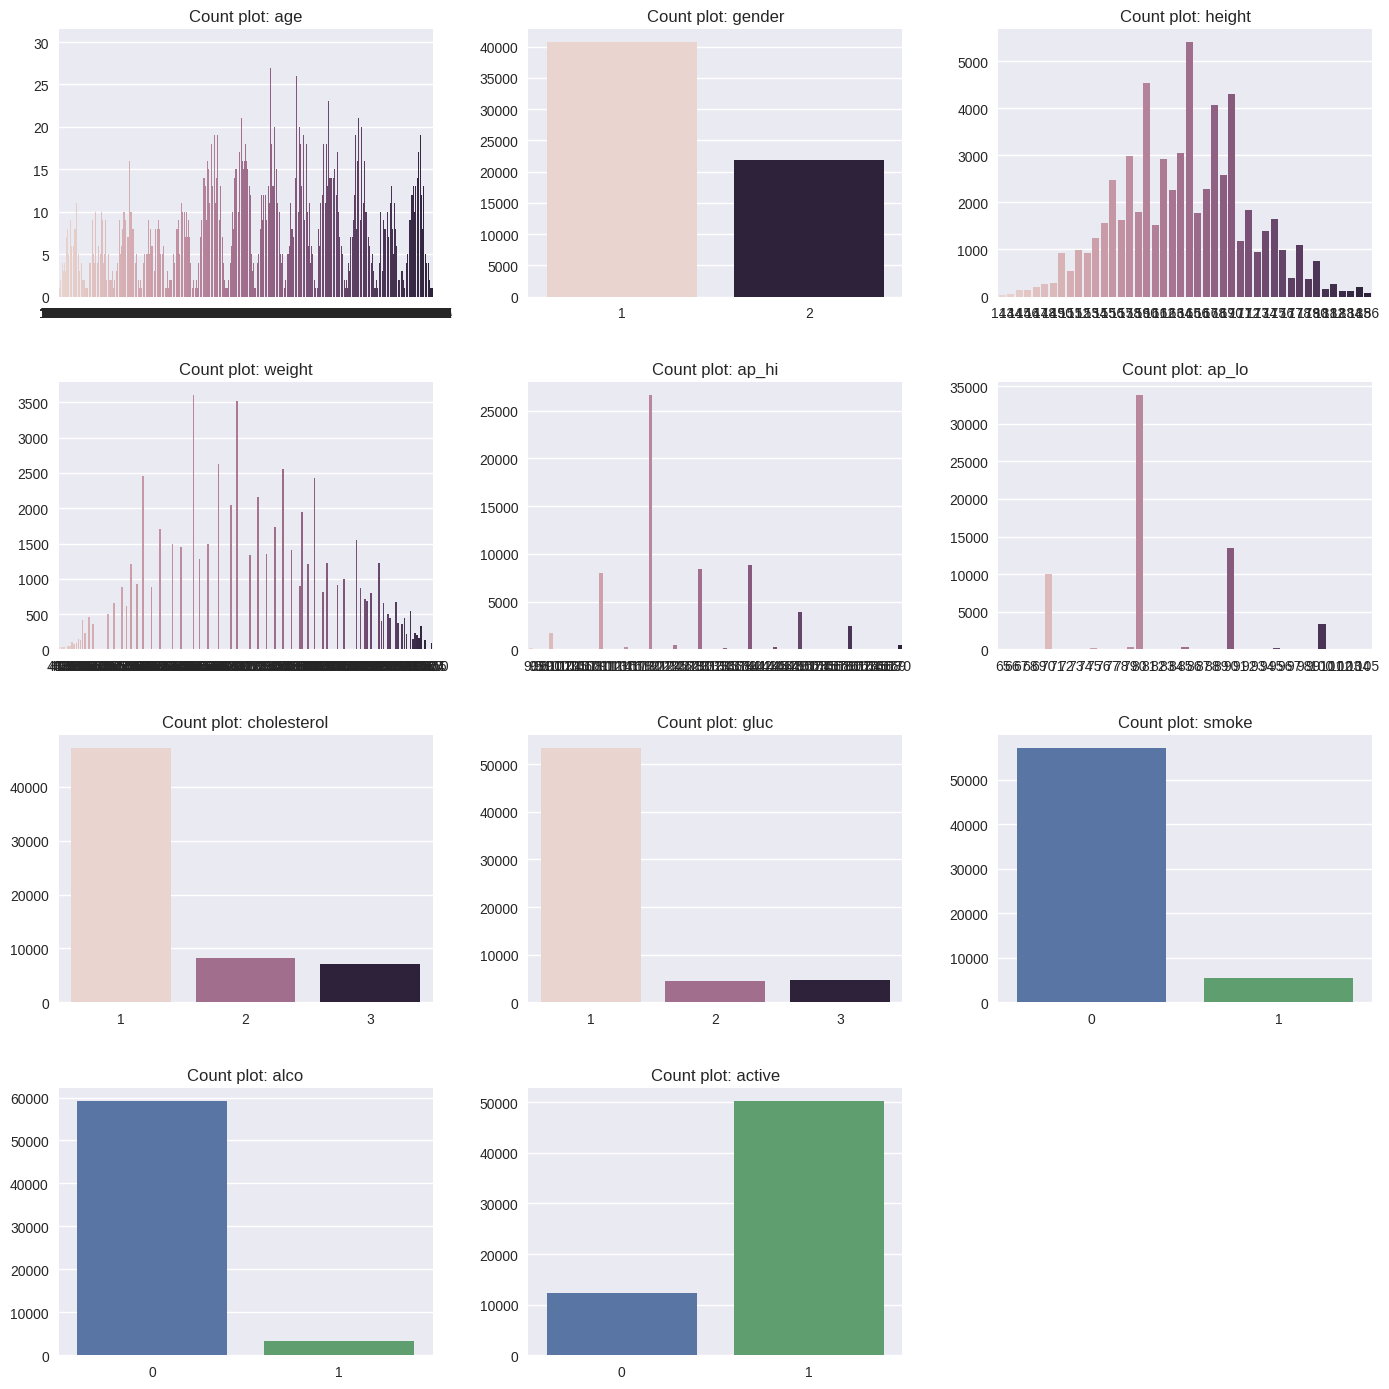

In [64]:
plt.style.use(plt.style.available[12])

N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, cat_feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Count plot: {cat_feature}")
    sns.countplot(data=df, x=cat_feature, hue=cat_feature, legend=False)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)

plt.show()

Histograms

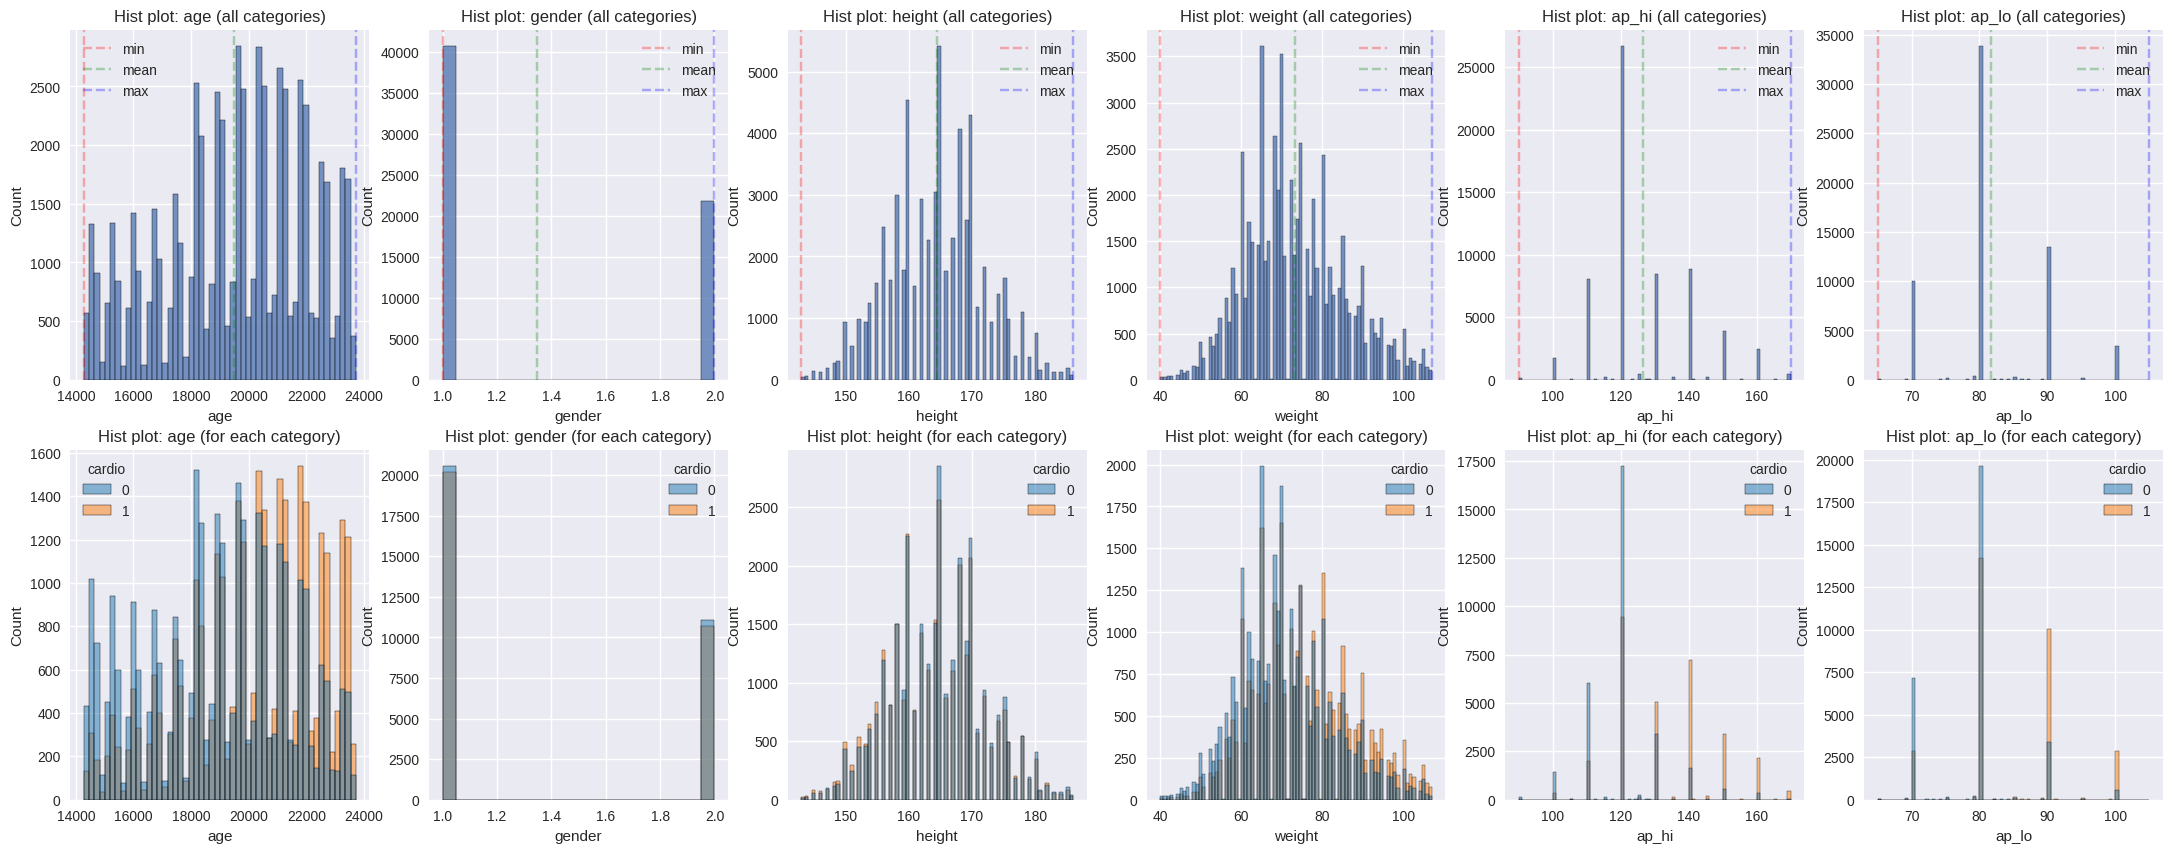

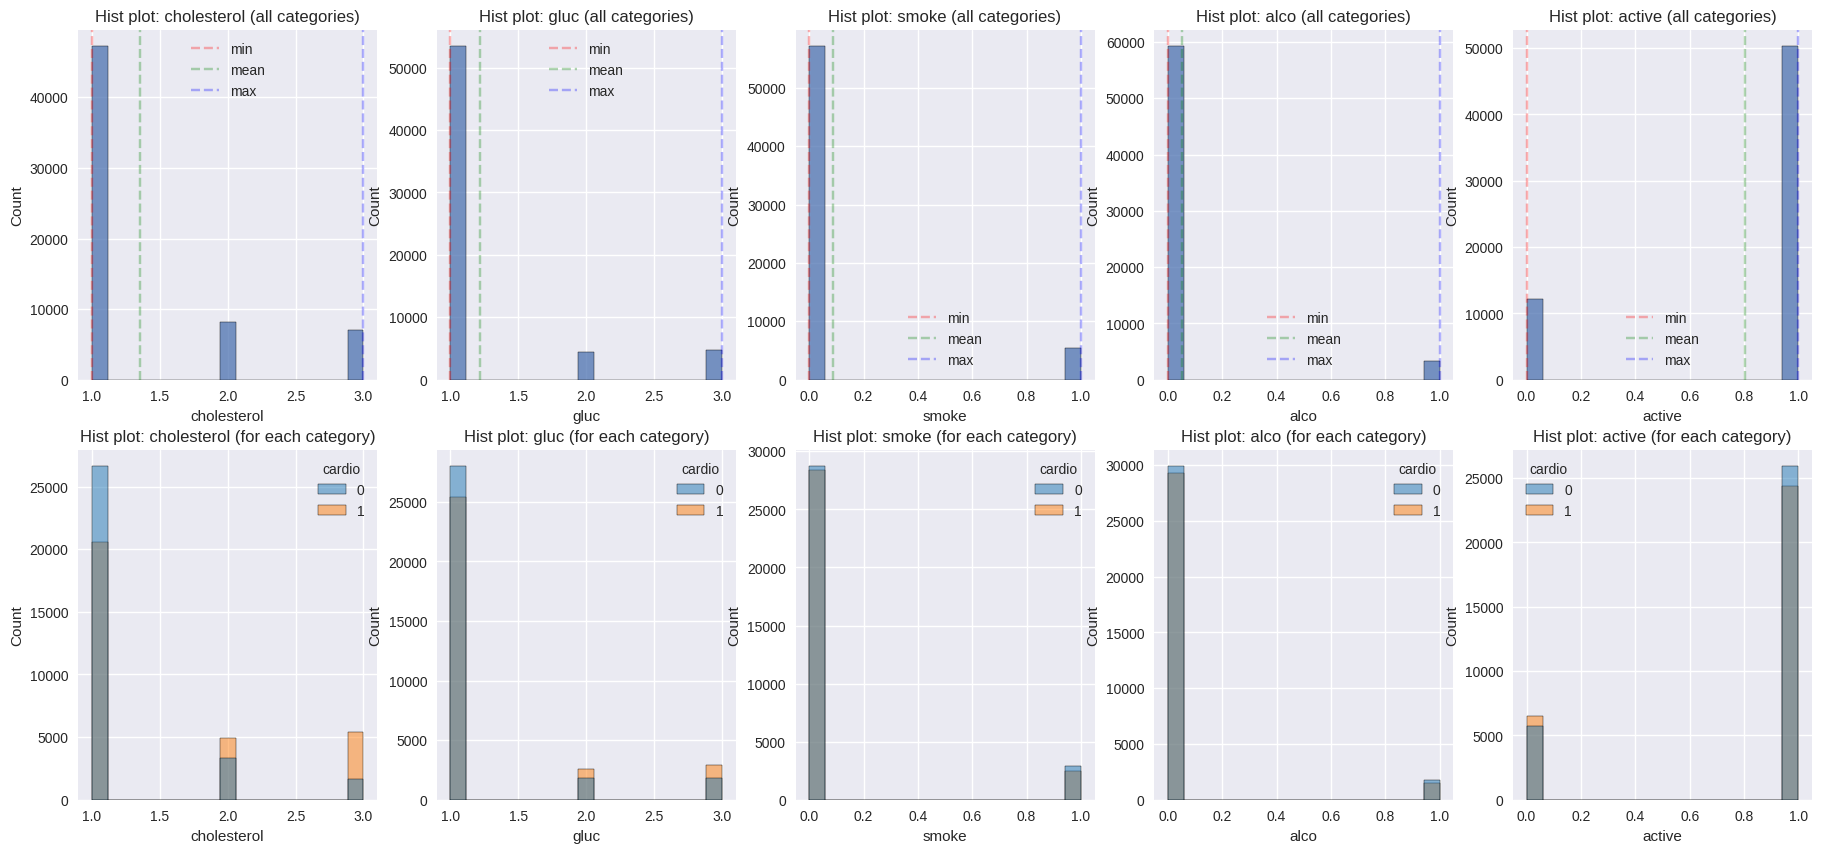

In [65]:
ROW_WIDTH = 6
temp = 0

numeric_features = [
    feature for feature in INPUT_FEATURES
    if df[feature].dtype in ['int64', 'float64', 'int32', 'float32']
    and feature not in ['bmi_category', 'hypertension_stage']
]

for num_feature in numeric_features:
    if temp == 0:
        plt.figure(figsize=(27,10))

    plt.subplot(2,ROW_WIDTH, temp + 1)
    plt.title(f"Hist plot: {num_feature} (all categories)")
    sns.histplot(df, x=num_feature, )

    plt.axvline(x= df[num_feature].min() , label="min", color='r', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].mean() , label="mean", color='g', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].max() , label="max", color='b', linestyle='--', alpha = 0.3)

    plt.legend()


    plt.subplot(2,ROW_WIDTH, (temp + 1) + ROW_WIDTH)
    plt.title(f"Hist plot: {num_feature} (for each category)")
    sns.histplot(df, x=num_feature, hue=TARGET, palette='tab10')

    if temp == ROW_WIDTH - 1:
        plt.show()

    temp = (temp + 1) % ROW_WIDTH

if temp != ROW_WIDTH - 1:
    plt.show()

Count of CVD vs No CVD

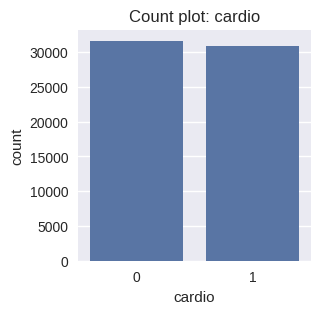

In [66]:
plt.figure(figsize=(3,3))
plt.title(f"Count plot: {TARGET}")
sns.countplot(df, x=TARGET)
plt.show()

Kernel Density Estimate (KDE) plots

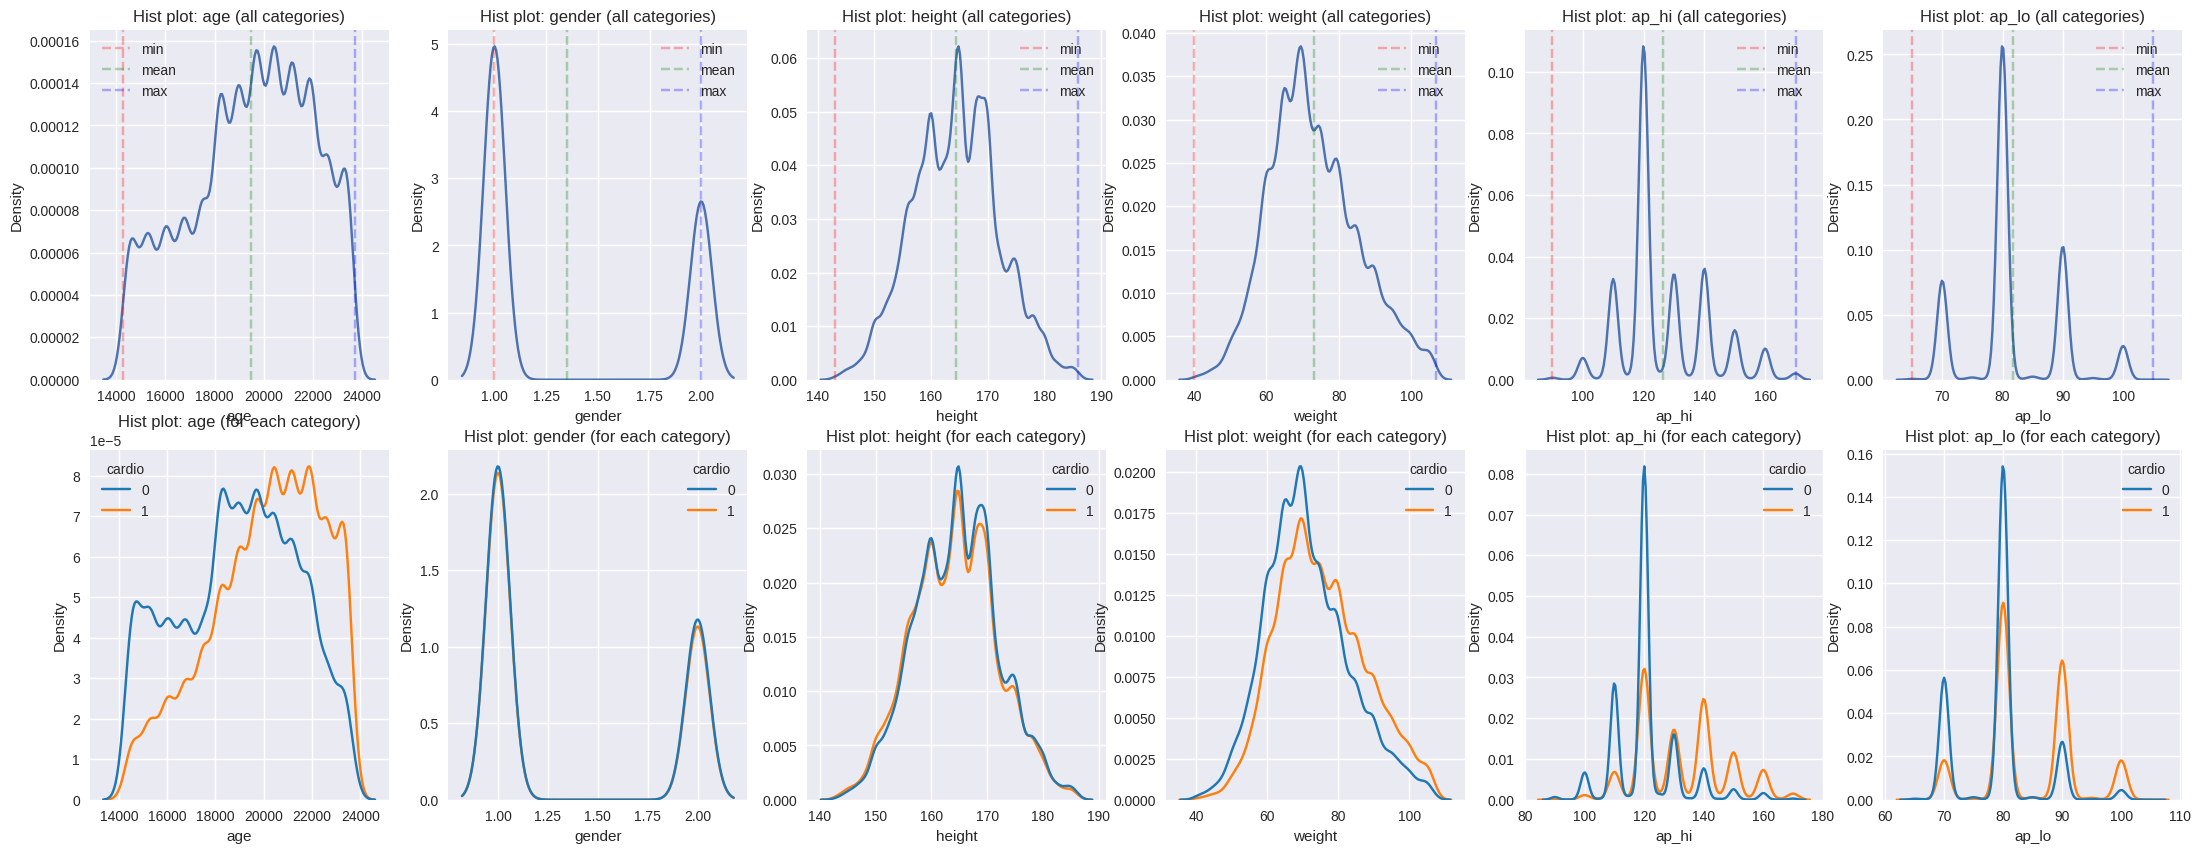

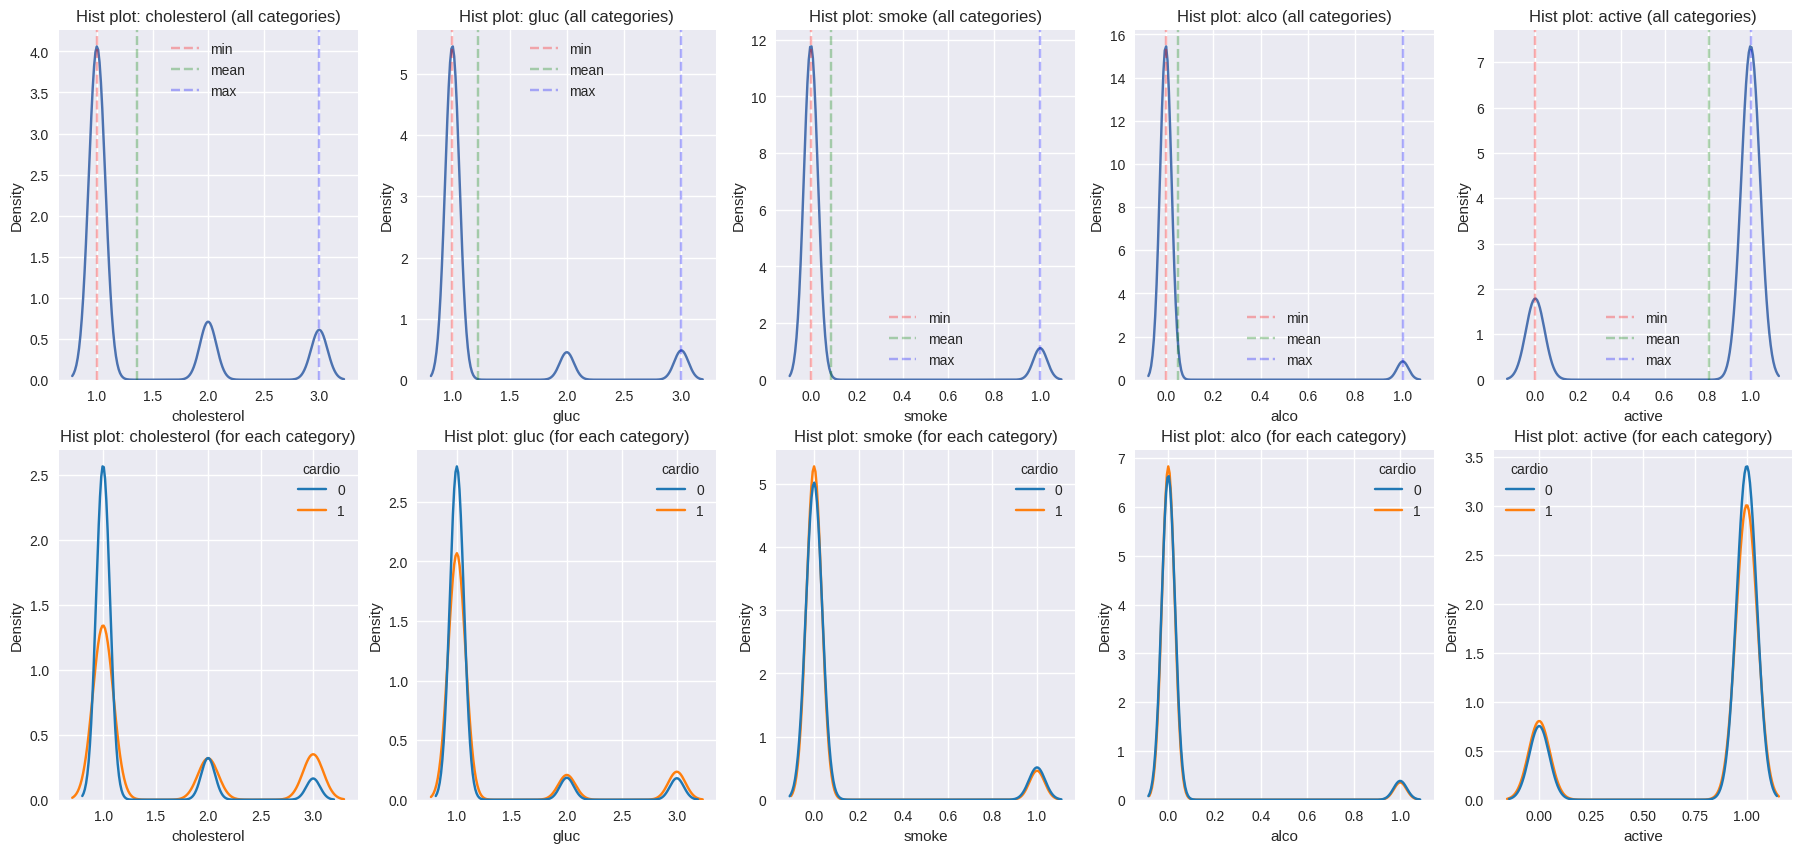

In [67]:
ROW_WIDTH = 6
temp = 0

numeric_features = [
    feature for feature in INPUT_FEATURES
    if df[feature].dtype in ['int64', 'float64', 'int32', 'float32']
    and feature not in ['bmi_category', 'hypertension_stage']
]

for num_feature in numeric_features:
    if temp == 0:
        plt.figure(figsize=(27,10))

    plt.subplot(2,ROW_WIDTH, temp + 1)
    plt.title(f"Hist plot: {num_feature} (all categories)")
    sns.kdeplot(df, x=num_feature, )

    plt.axvline(x= df[num_feature].min() , label="min", color='r', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].mean() , label="mean", color='g', linestyle='--', alpha = 0.3)
    plt.axvline(x= df[num_feature].max() , label="max", color='b', linestyle='--', alpha = 0.3)

    plt.legend()


    plt.subplot(2,ROW_WIDTH, (temp + 1) + ROW_WIDTH)
    plt.title(f"Hist plot: {num_feature} (for each category)")
    sns.kdeplot(df, x=num_feature, hue=TARGET, palette='tab10')

    if temp == ROW_WIDTH - 1:
        plt.show()

    temp = (temp + 1) % ROW_WIDTH

if temp != ROW_WIDTH - 1:
    plt.show()

Box-plots

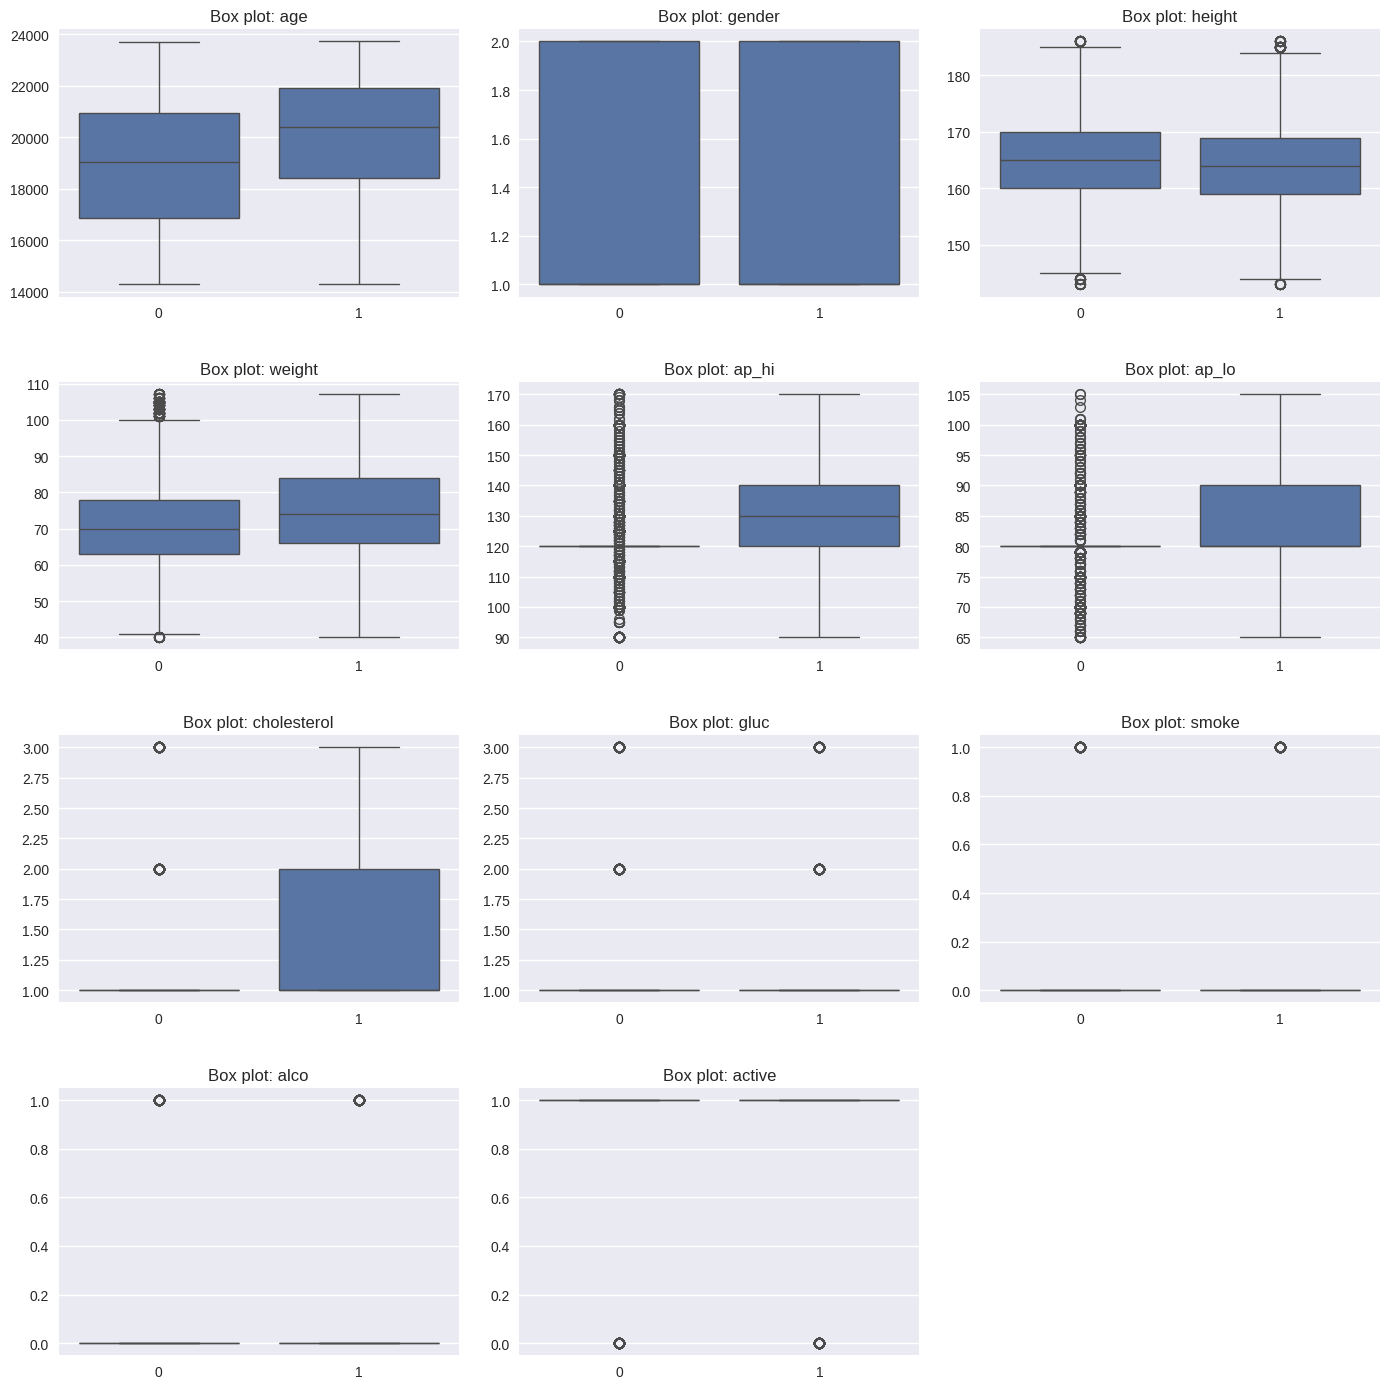

In [68]:
N_COLS = 3
N_ROWS = math.ceil(len(INPUT_FEATURES) / N_COLS)

plt.figure(figsize=(14, 3.5 * N_ROWS))

for i, feature in enumerate(INPUT_FEATURES):
    plt.subplot(N_ROWS, N_COLS, i+1)
    plt.title(f"Box plot: {feature}")
    sns.boxplot(df, x=TARGET, y=feature)
    plt.ylabel("")
    plt.xlabel('')

plt.tight_layout(h_pad=3.0, w_pad=2.0)
plt.show()

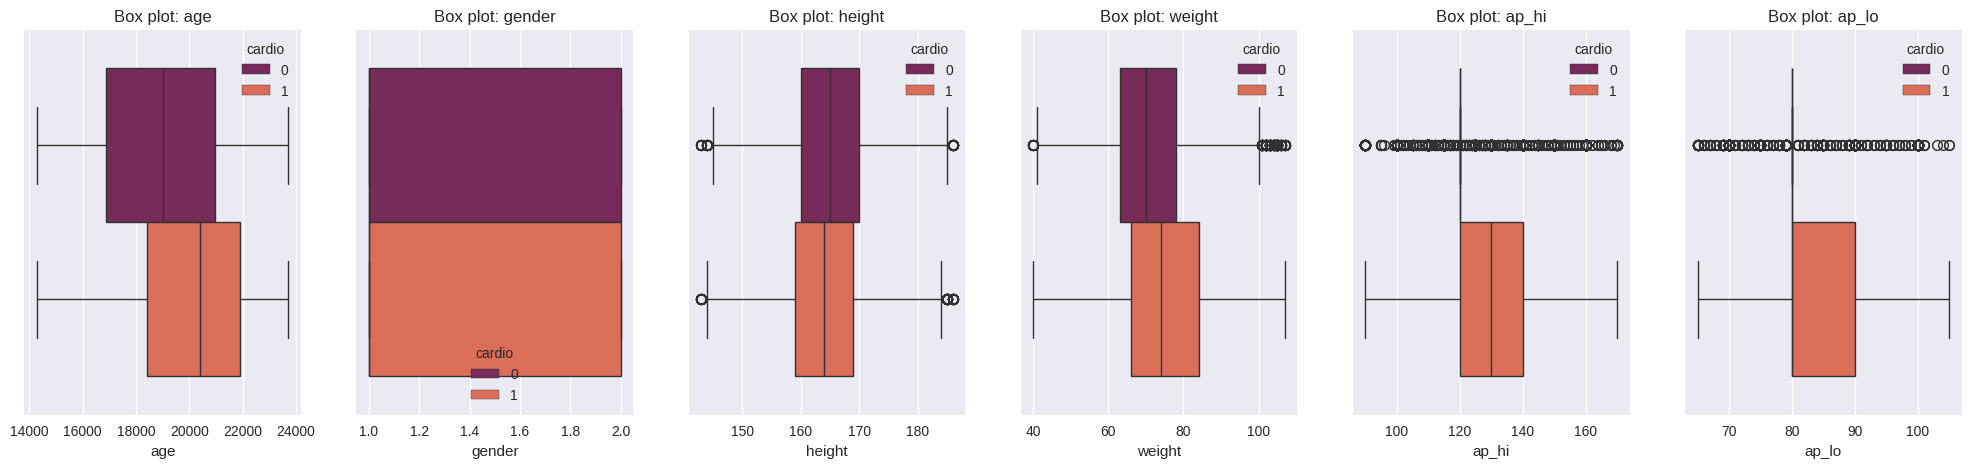

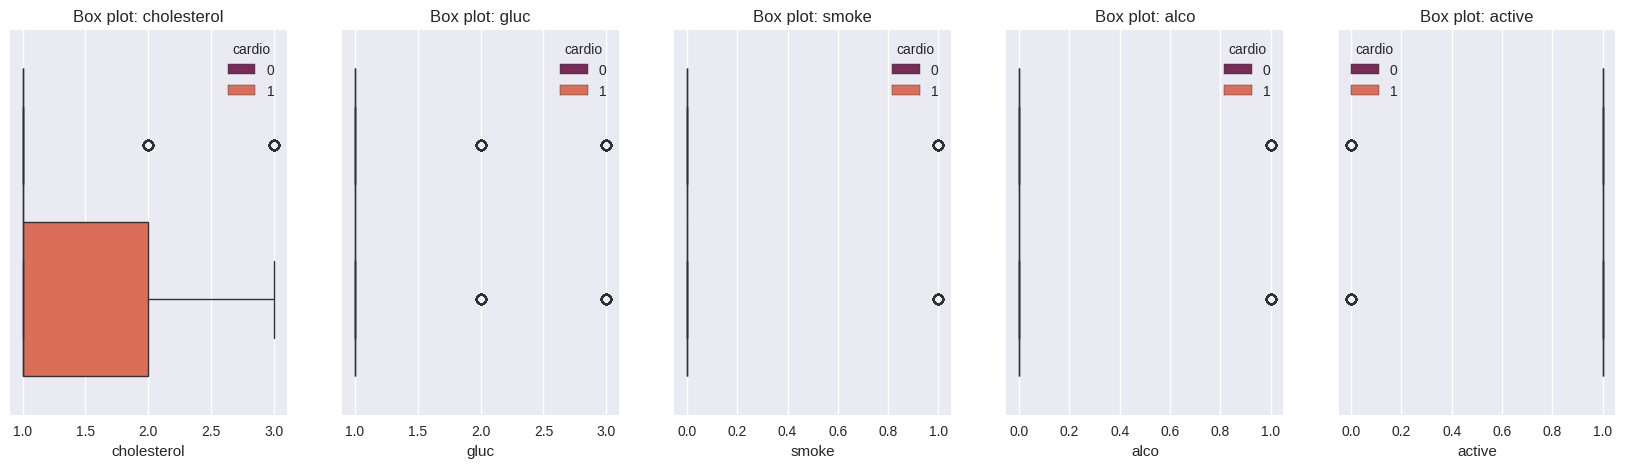

In [69]:
def plot_box(features, hue):
    ROW_WIDTH = 6
    temp = 0

    for num_feature in features:
        if temp == 0:
            plt.figure(figsize=(25,5))

        plt.subplot(1,ROW_WIDTH, temp + 1)
        plt.title(f"Box plot: {num_feature}")
        sns.boxplot(df, x=num_feature, hue=hue, palette='rocket')

        if temp == ROW_WIDTH - 1:
            plt.show()

        temp = (temp + 1) % ROW_WIDTH

    if temp != ROW_WIDTH - 1:
        plt.show()

plot_box(INPUT_FEATURES, TARGET)

Scatter-plots

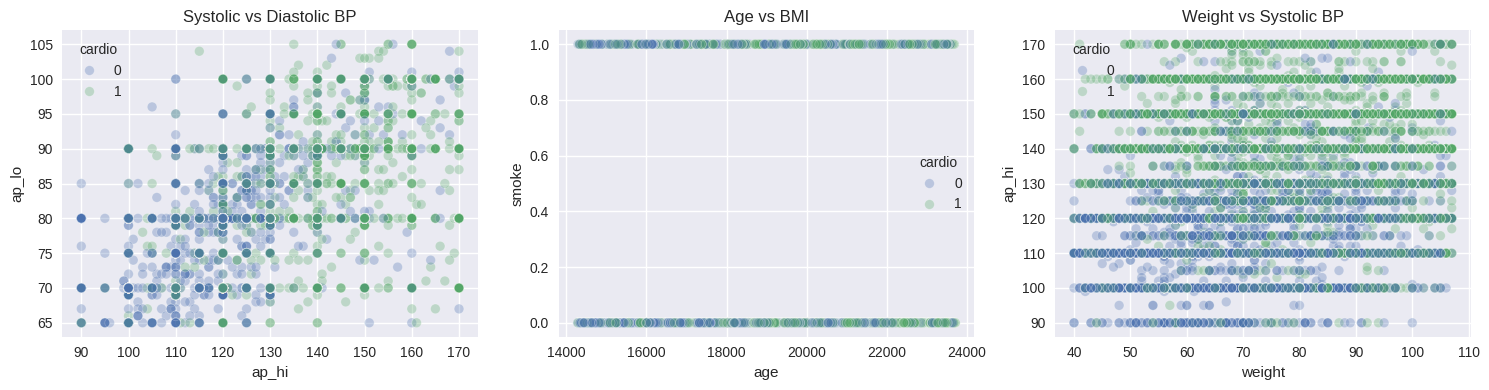

In [70]:
#Scatter plots
plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
sns.scatterplot(df, x='ap_hi', y='ap_lo', hue=TARGET, alpha=0.3)
plt.title("Systolic vs Diastolic BP")

plt.subplot(1,3,2)
sns.scatterplot(df, x='age', y='smoke', hue=TARGET, alpha=0.3)
plt.title("Age vs BMI")

plt.subplot(1,3,3)
sns.scatterplot(df, x='weight', y='ap_hi', hue=TARGET, alpha=0.3)
plt.title("Weight vs Systolic BP")

plt.tight_layout()
plt.show()

Confusion Matrix

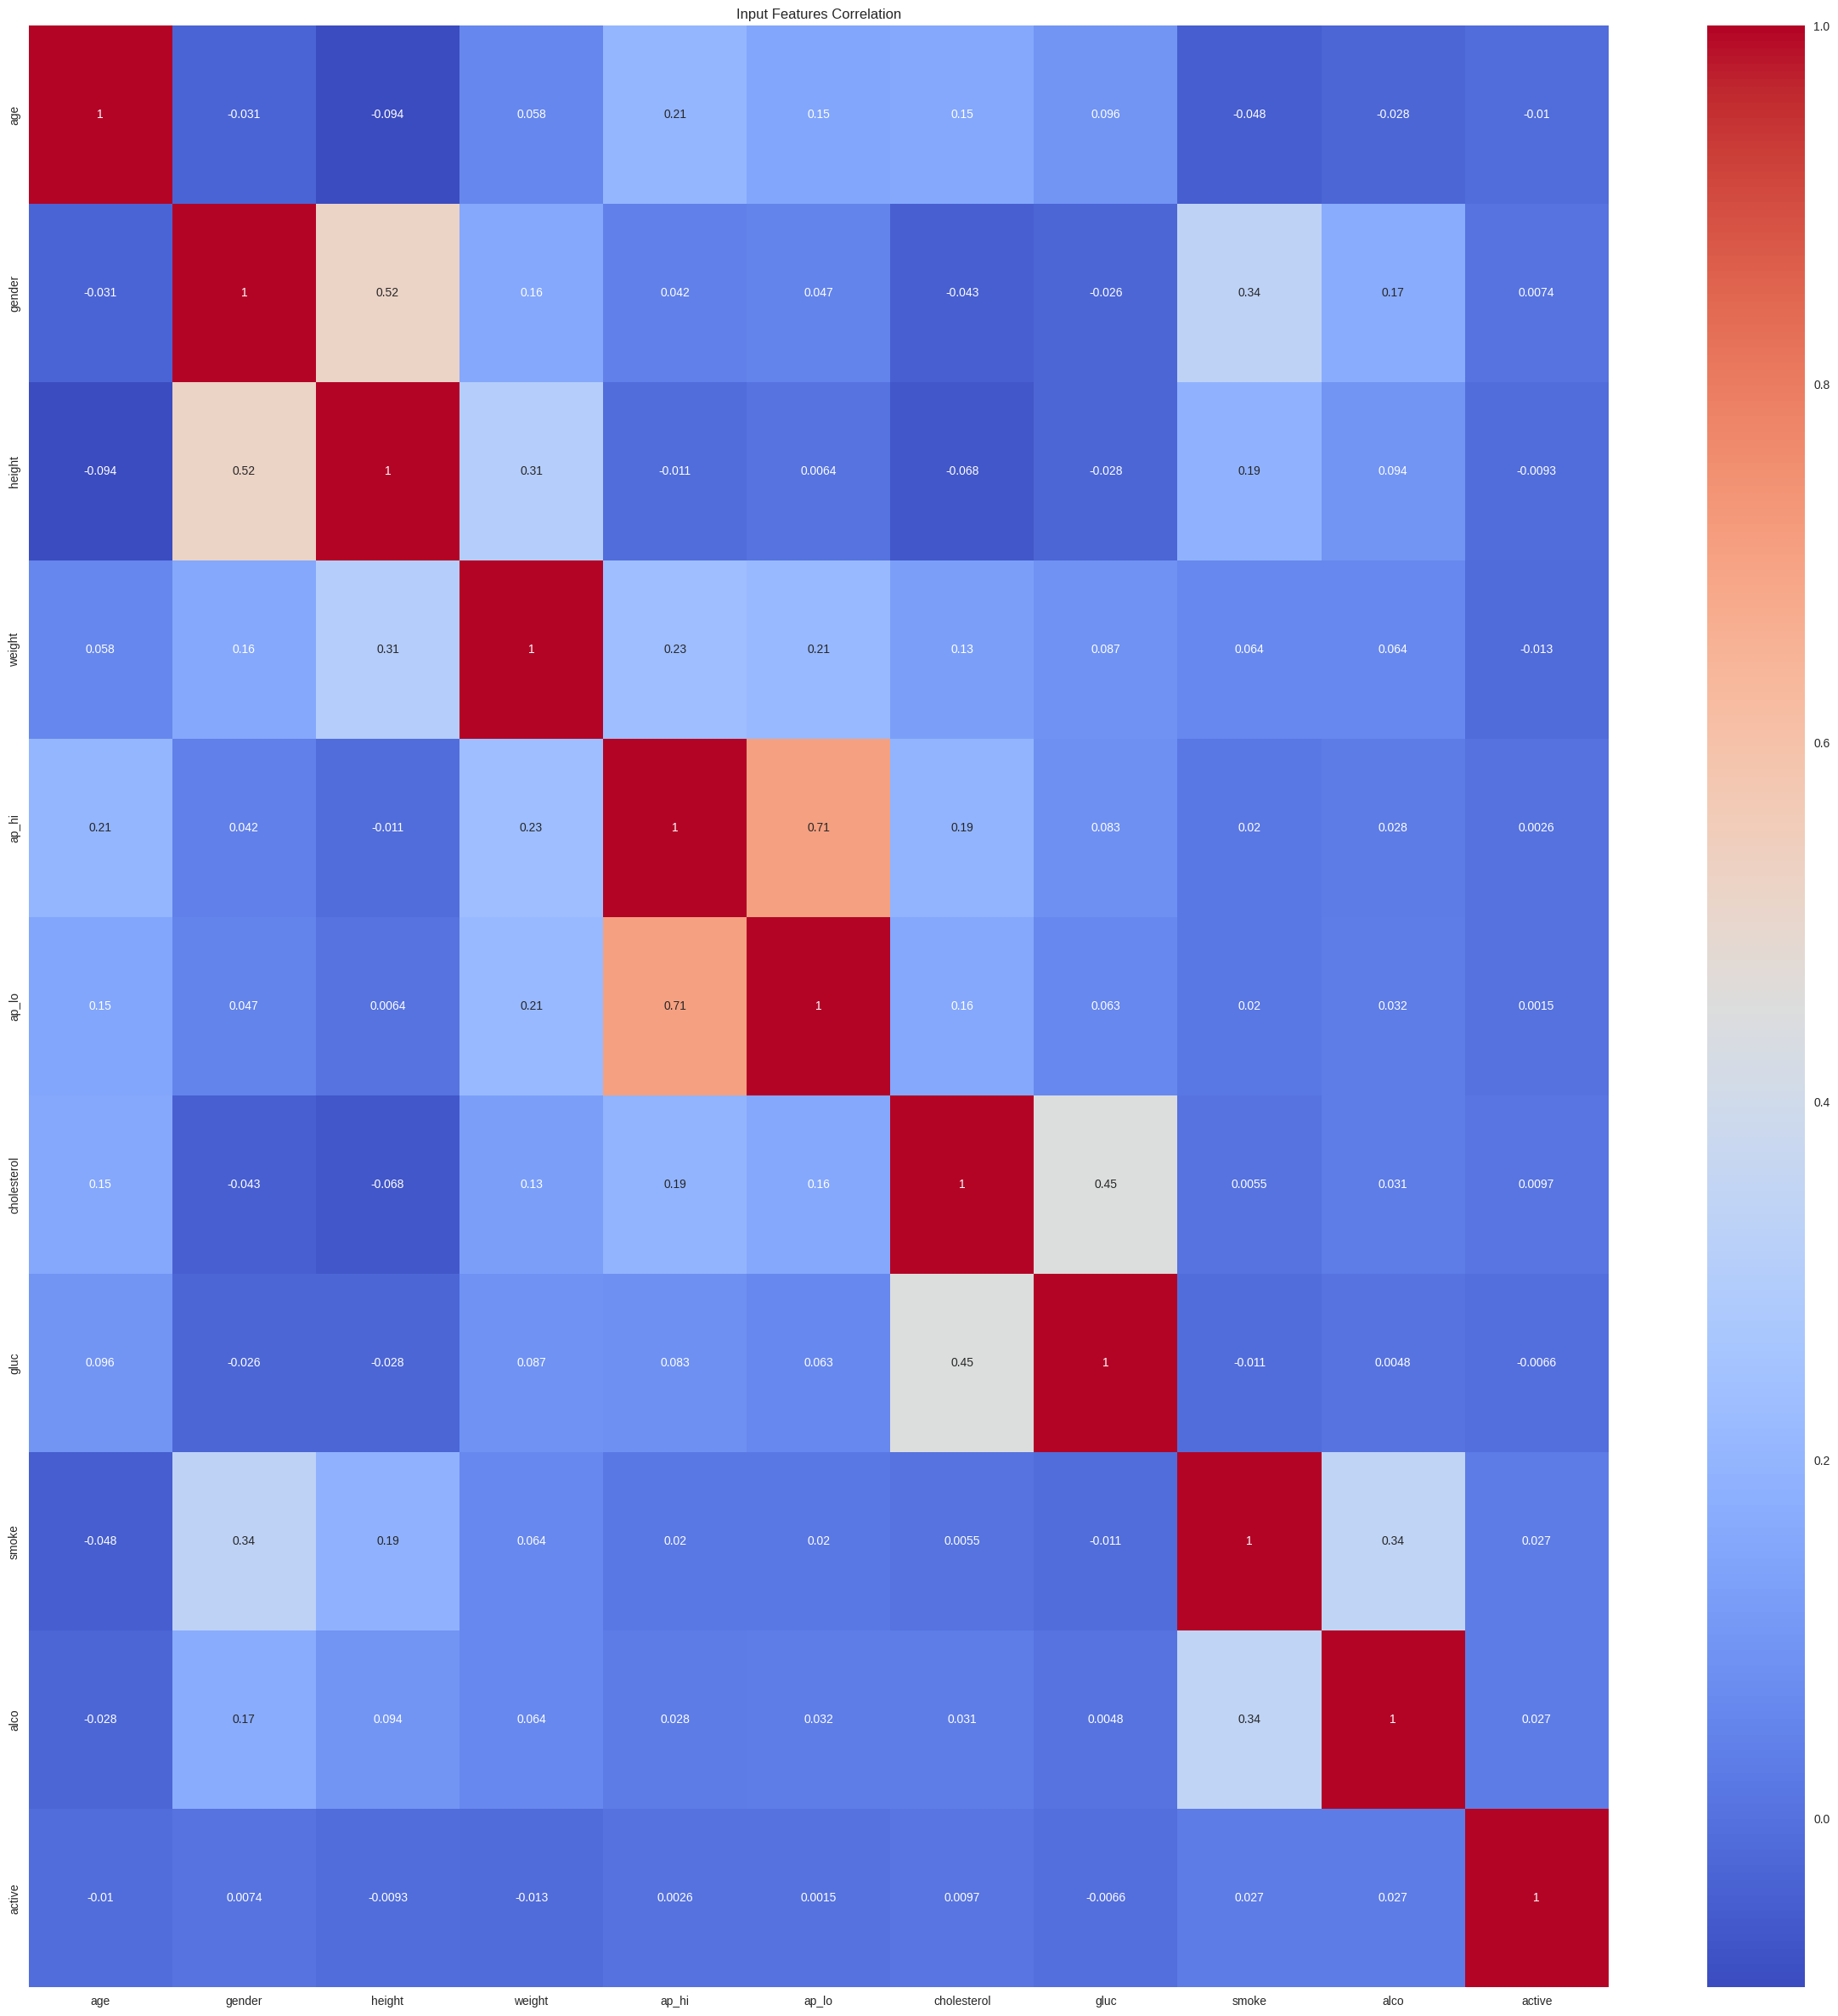

In [71]:
plt.figure(figsize=(30, 30))

plt.title("Input Features Correlation")

sns.heatmap(
    df[INPUT_FEATURES].corr(),
    annot=True,
    cmap='coolwarm',
    )

plt.show()

# **CORRELATION ANALYSIS MISSING**

# **Feature Engineering**

In [72]:
INPUT_FEATURES

['age',
 'gender',
 'height',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active']

In [73]:
df.head(5)

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,21914,1,151,67.0,120,80,2,2,0,0,0,0


Age in years

In [74]:
df['age_years'] = (df['age'] / 365).round().astype(int)

Height in meters

In [75]:
df['height_m'] = df['height'] / 100

BMI

In [76]:
df['bmi'] = df['weight'] / (df['height_m'] ** 2)

Pulse pressure

In [77]:
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

Health index

In [78]:
df['health_index'] = (df['active'] * 1) - (df['smoke'] * 0.5) - (df['alco'] * 0.5)

Cholestrol glucose interaction

In [79]:
df['cholesterol_gluc_interaction'] = df['cholesterol'] * df['gluc']

Mean Arterial Pressure (MAP)

In [80]:
df['map'] = (df['ap_hi'] + 2 * df['ap_lo']) / 3

BMI category

In [81]:
df['bmi_category'] = pd.cut(
    df['bmi'],
    bins=[0, 18.5, 25, 30, np.inf],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
)

Hypertension-stage

In [82]:
def bp_category(row):
    systolic = row['ap_hi']
    diastolic = row['ap_lo']
    if systolic < 120 and diastolic < 80:
        return 'Normal'
    elif systolic < 130 and diastolic < 80:
        return 'Elevated'
    elif systolic < 140 or diastolic < 90:
        return 'Stage 1'
    else:
        return 'Stage 2'

df['hypertension_stage'] = df.apply(bp_category, axis=1)

In [83]:
new_features = [
    'age_years', 'bmi', 'pulse_pressure', 'health_index',
    'cholesterol_gluc_interaction', 'map', 'bmi_category', 'hypertension_stage'
]

INPUT_FEATURES = INPUT_FEATURES + [f for f in new_features if f not in INPUT_FEATURES]

Dropping unwanted values

In [84]:
df = drop_unwanted_features(df, 'age')
df = drop_unwanted_features(df, 'height')


Dropping feature: age

Dropping feature: height


In [85]:
df.columns

Index(['gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke',
       'alco', 'active', 'cardio', 'age_years', 'height_m', 'bmi',
       'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map',
       'bmi_category', 'hypertension_stage'],
      dtype='object')

In [86]:
INPUT_FEATURES = [
    'gender', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active', 'age_years', 'bmi', 'pulse_pressure',
    'health_index', 'cholesterol_gluc_interaction', 'map',
    'bmi_category', 'hypertension_stage'
]

In [87]:
INPUT_FEATURES

['gender',
 'weight',
 'ap_hi',
 'ap_lo',
 'cholesterol',
 'gluc',
 'smoke',
 'alco',
 'active',
 'age_years',
 'bmi',
 'pulse_pressure',
 'health_index',
 'cholesterol_gluc_interaction',
 'map',
 'bmi_category',
 'hypertension_stage']

# **Feature selection**

Dataset-splitting

In [88]:
#Dataset splitting
X_train, X_test, y_train, y_test = train_test_split(
    df[INPUT_FEATURES], df[TARGET],
    test_size=0.20,
    random_state=1234,
    stratify=df[TARGET]
)

print(f"{X_train.shape= }")
print(f"{y_train.shape= }")
print(f"{X_test.shape= }")
print(f"{y_test.shape= }")

#Encoding categorical engineered features
CATEGORICAL_TO_ENCODE = ['bmi_category', 'hypertension_stage']

X_train_encoded = pd.get_dummies(X_train, columns=CATEGORICAL_TO_ENCODE, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=CATEGORICAL_TO_ENCODE, drop_first=True)

# Align test set columns to train set (handles any category missing from one split)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

X_train.shape= (49999, 17)
y_train.shape= (49999,)
X_test.shape= (12500, 17)
y_test.shape= (12500,)


Correlation matrix after feature engineering

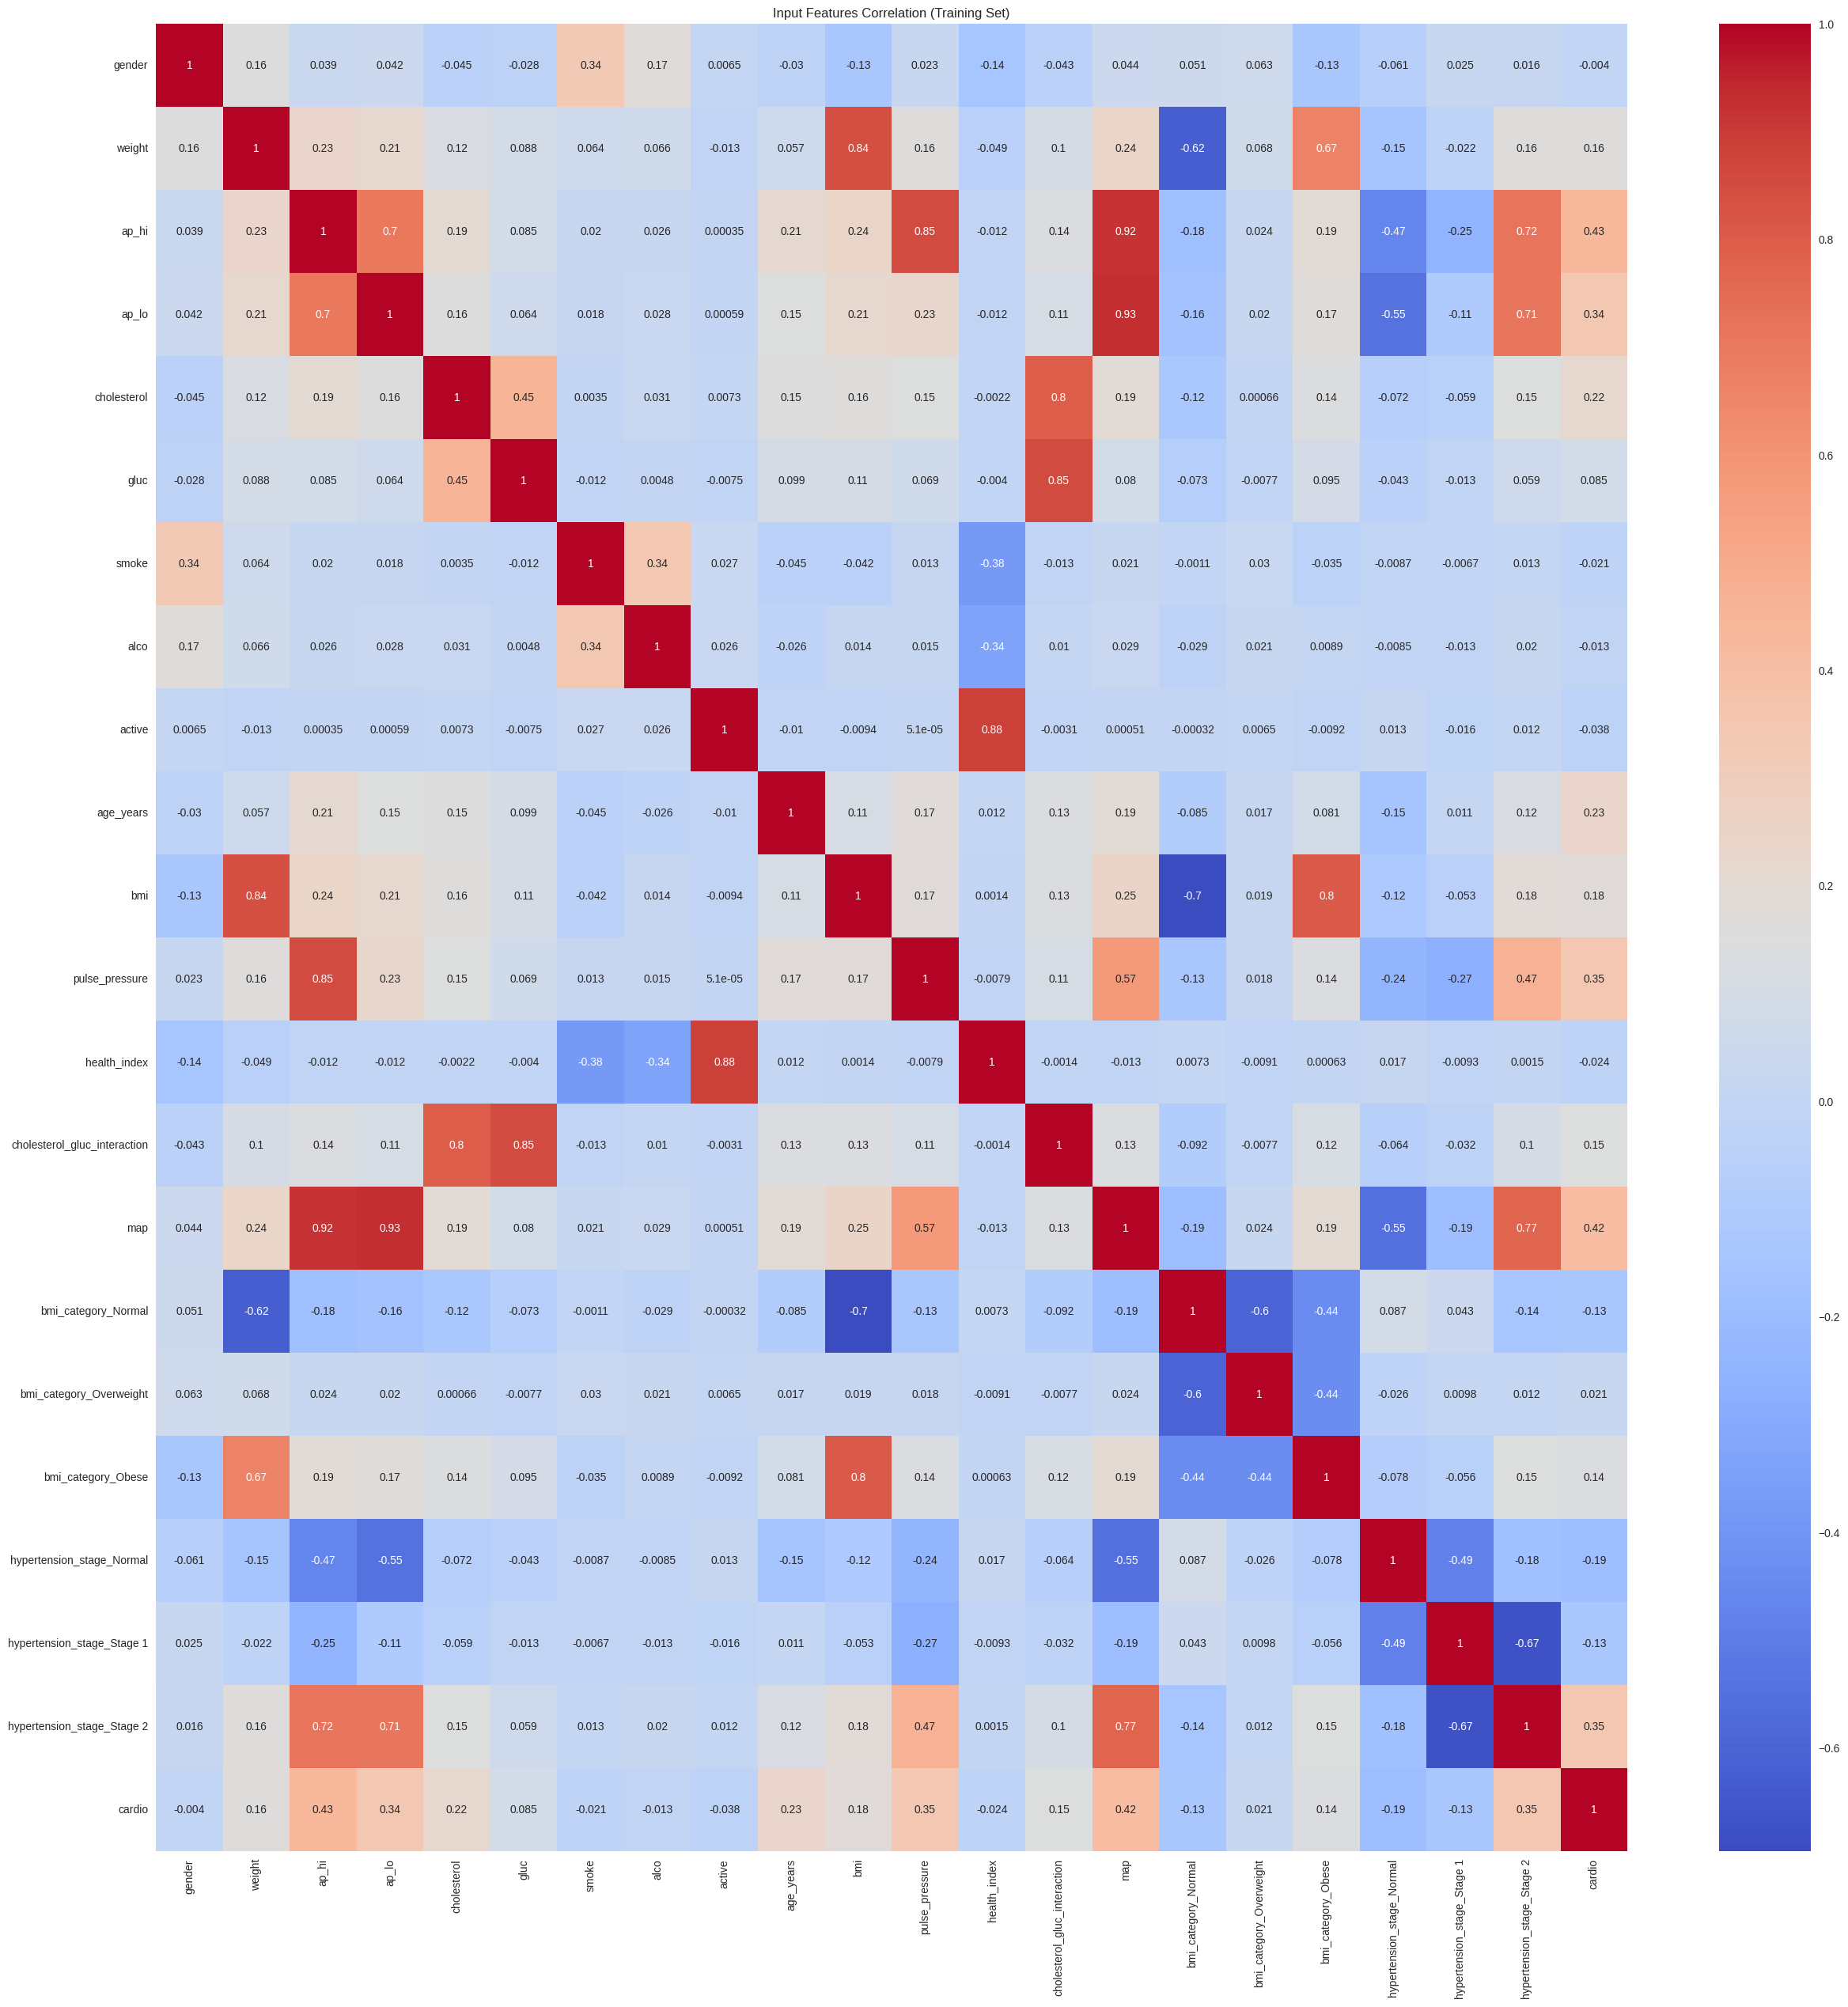

gender                             : F-value =    0.796, p-value = 0.3723
weight                             : F-value = 1290.217, p-value = 0.0000
ap_hi                              : F-value = 11608.604, p-value = 0.0000
ap_lo                              : F-value = 6454.666, p-value = 0.0000
cholesterol                        : F-value = 2461.135, p-value = 0.0000
gluc                               : F-value =  360.913, p-value = 0.0000
smoke                              : F-value =   23.004, p-value = 0.0000
alco                               : F-value =    9.012, p-value = 0.0027
active                             : F-value =   73.162, p-value = 0.0000
age_years                          : F-value = 2858.333, p-value = 0.0000
bmi                                : F-value = 1596.439, p-value = 0.0000
pulse_pressure                     : F-value = 6814.176, p-value = 0.0000
health_index                       : F-value =   29.306, p-value = 0.0000
cholesterol_gluc_interaction       : 

In [89]:
plt.figure(figsize=(30, 30))
plt.title("Input Features Correlation (Training Set)")

sns.heatmap(
    pd.concat([X_train_encoded, y_train], axis=1).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

#Feature selection (ANOVA F-test on training set only)
f_values, p_values = f_classif(X_train_encoded, y_train)

for feature, f_val, p_val in zip(X_train_encoded.columns, f_values, p_values):
    print(f"{feature:35s}: F-value = {f_val:8.3f}, p-value = {p_val:.4f}")

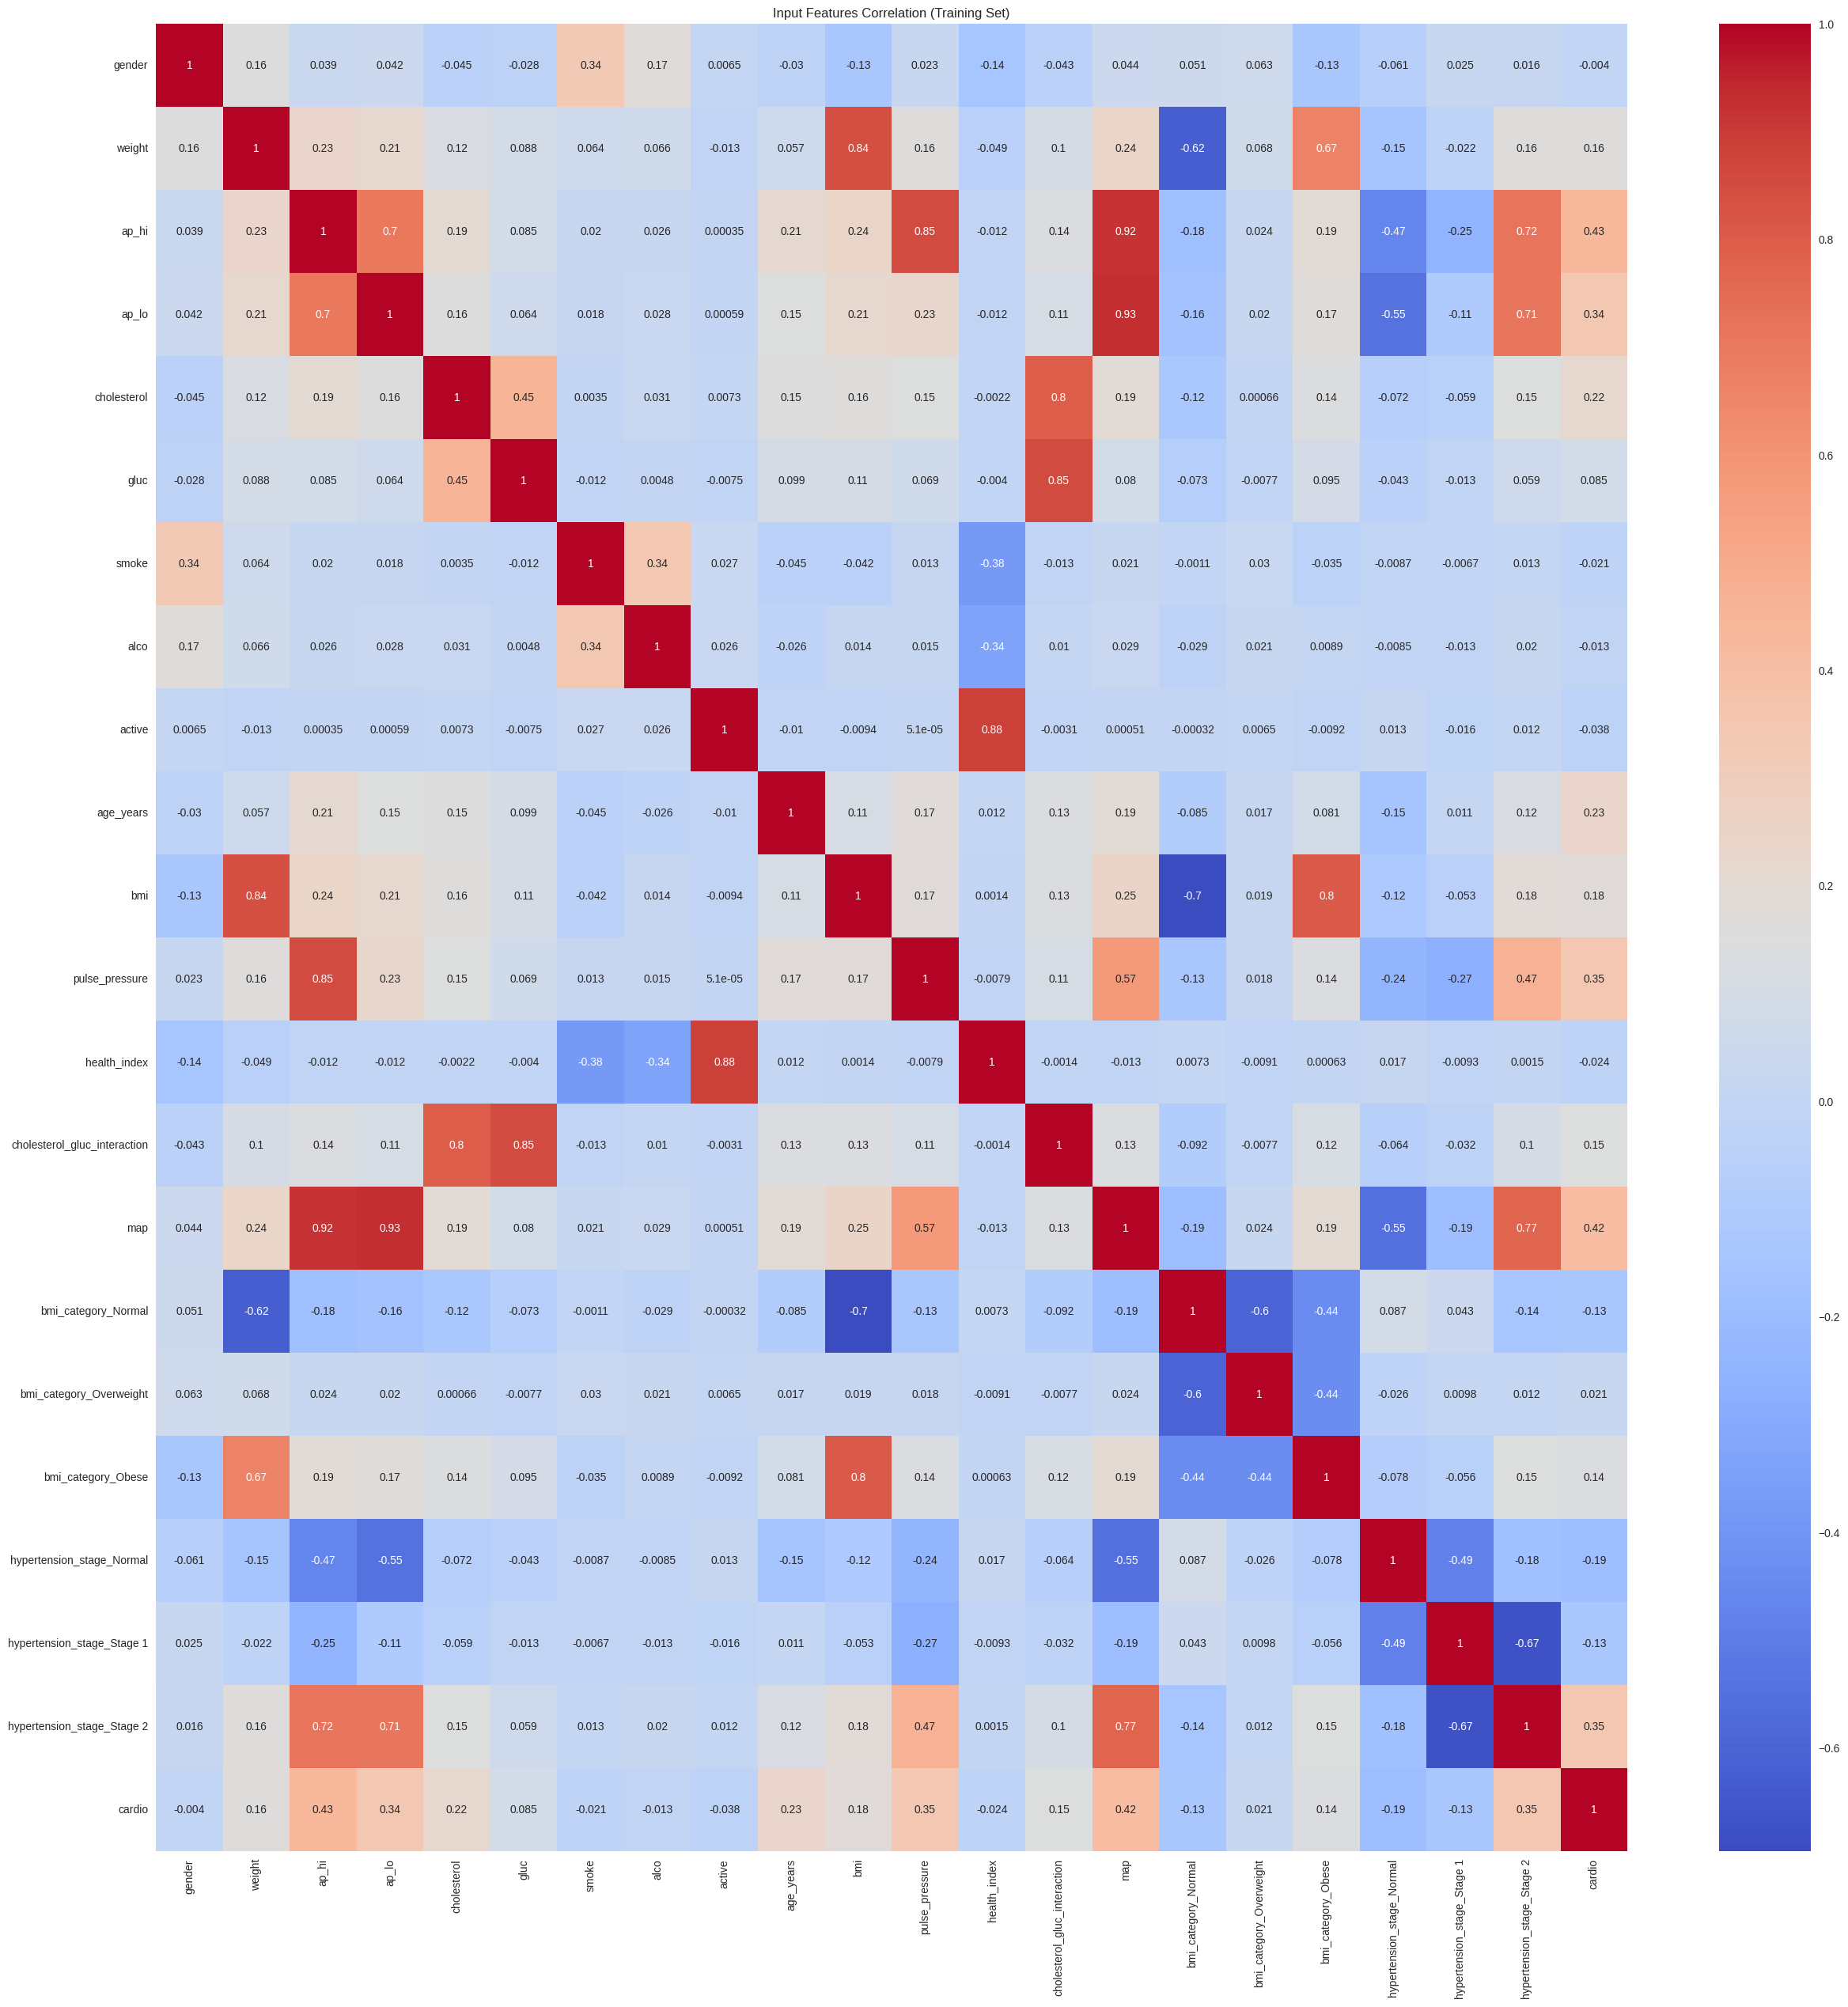

gender                             : F-value =    0.796, p-value = 0.3723
weight                             : F-value = 1290.217, p-value = 0.0000
ap_hi                              : F-value = 11608.604, p-value = 0.0000
ap_lo                              : F-value = 6454.666, p-value = 0.0000
cholesterol                        : F-value = 2461.135, p-value = 0.0000
gluc                               : F-value =  360.913, p-value = 0.0000
smoke                              : F-value =   23.004, p-value = 0.0000
alco                               : F-value =    9.012, p-value = 0.0027
active                             : F-value =   73.162, p-value = 0.0000
age_years                          : F-value = 2858.333, p-value = 0.0000
bmi                                : F-value = 1596.439, p-value = 0.0000
pulse_pressure                     : F-value = 6814.176, p-value = 0.0000
health_index                       : F-value =   29.306, p-value = 0.0000
cholesterol_gluc_interaction       : 

In [90]:
#Correlation Matrix (training set only)
plt.figure(figsize=(30, 30))
plt.title("Input Features Correlation (Training Set)")

sns.heatmap(
    pd.concat([X_train_encoded, y_train], axis=1).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

#Feature selection (ANOVA F-test on training set only)
f_values, p_values = f_classif(X_train_encoded, y_train)

for feature, f_val, p_val in zip(X_train_encoded.columns, f_values, p_values):
    print(f"{feature:35s}: F-value = {f_val:8.3f}, p-value = {p_val:.4f}")

In [91]:
#Finalize selected features
ALPHA = 0.05
SELECTED_FEATURES = [
    feature for feature, p in zip(X_train_encoded.columns, p_values) if p < ALPHA
]

print(f"Selected {len(SELECTED_FEATURES)} of {X_train_encoded.shape[1]} features at alpha={ALPHA}:")
print(SELECTED_FEATURES)

X_train_selected = X_train_encoded[SELECTED_FEATURES]
X_test_selected = X_test_encoded[SELECTED_FEATURES]

Selected 20 of 21 features at alpha=0.05:
['weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years', 'bmi', 'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map', 'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese', 'hypertension_stage_Normal', 'hypertension_stage_Stage 1', 'hypertension_stage_Stage 2']


Before min-max scaling

In [92]:
df.describe()

,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map
count,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000
mean,1.348550,73.180473,126.421847,81.698267,1.357734,1.220660,0.086337,0.052161,0.804333,0.493896,53.407463,1.644055,27.120124,44.723580,0.735084,1.829821,96.606127
std,0.476515,12.271325,14.288637,7.672536,0.675215,0.567613,0.280864,0.222353,0.396717,0.499967,6.739995,0.075310,4.567655,10.402982,0.441274,1.860473,9.124194
min,1.000000,40.000000,90.000000,65.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,39.000000,1.430000,13.520822,5.000000,-1.000000,1.000000,73.333333
25%,1.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,49.000000,1.590000,23.875115,40.000000,0.500000,1.000000,93.333333
50%,1.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,54.000000,1.650000,26.233556,40.000000,1.000000,1.000000,93.333333
75%,2.000000,81.000000,140.000000,90.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.000000,1.700000,29.760838,50.000000,1.000000,2.000000,103.333333
max,2.000000,107.000000,170.000000,105.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,65.000000,1.860000,50.891795,103.000000,1.000000,9.000000,126.000000


Min-max scaling happens after eda to not mess up visualizations and after feature engineering to not distort values

In [93]:
NON_SCALE_FEATURES = ['gluc', 'alco', 'smoke', 'cholesterol', 'active']

cols_to_scale = [
    col for col in X_train_selected.columns
    if col not in NON_SCALE_FEATURES
    and not col.startswith('bmi_category_')
    and not col.startswith('hypertension_stage_')
]

standard_scaler = StandardScaler()

X_train_scaled = X_train_selected.copy()
X_test_scaled = X_test_selected.copy()

X_train_scaled[cols_to_scale] = standard_scaler.fit_transform(X_train_selected[cols_to_scale])
X_test_scaled[cols_to_scale] = standard_scaler.transform(X_test_selected[cols_to_scale])

print(f"Scaled columns: {cols_to_scale}")


Scaled columns: ['weight', 'ap_hi', 'ap_lo', 'age_years', 'bmi', 'pulse_pressure', 'health_index', 'cholesterol_gluc_interaction', 'map']


After min-max scaling

In [94]:
df.describe()

,gender,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,height_m,bmi,pulse_pressure,health_index,cholesterol_gluc_interaction,map
count,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000,62499.000000
mean,1.348550,73.180473,126.421847,81.698267,1.357734,1.220660,0.086337,0.052161,0.804333,0.493896,53.407463,1.644055,27.120124,44.723580,0.735084,1.829821,96.606127
std,0.476515,12.271325,14.288637,7.672536,0.675215,0.567613,0.280864,0.222353,0.396717,0.499967,6.739995,0.075310,4.567655,10.402982,0.441274,1.860473,9.124194
min,1.000000,40.000000,90.000000,65.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,39.000000,1.430000,13.520822,5.000000,-1.000000,1.000000,73.333333
25%,1.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,49.000000,1.590000,23.875115,40.000000,0.500000,1.000000,93.333333
50%,1.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,54.000000,1.650000,26.233556,40.000000,1.000000,1.000000,93.333333
75%,2.000000,81.000000,140.000000,90.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,58.000000,1.700000,29.760838,50.000000,1.000000,2.000000,103.333333
max,2.000000,107.000000,170.000000,105.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000,65.000000,1.860000,50.891795,103.000000,1.000000,9.000000,126.000000


# **MODEL TRAINING**

In [95]:
CACHE_MODELS_DIR_NAME = 'models_cache'
os.makedirs(CACHE_MODELS_DIR_NAME, exist_ok=True)

In [96]:
class CustomModel:
    def __init__(self, name, model, extra_train_param=None):
        self.name = str(name)
        self.model = model
        self.extra_train_param = extra_train_param

        self.y_train_hat = None
        self.y_test_hat = None
        self.feature_names = None  # هنخزن الأعمدة هنا

        self.load()

    def fit(self, x_train, y_train):
        if not getattr(self, "trained", False):
            if self.extra_train_param is None:
                self.model.fit(x_train, y_train)
            else:
                self.model.fit(x_train, y_train, **self.extra_train_param)

            self.feature_names = list(x_train.columns)

            self.trained = True
            self.save()

    def _align_features(self, X):
        if self.feature_names is not None:
            missing_cols = set(self.feature_names) - set(X.columns)
            extra_cols = set(X.columns) - set(self.feature_names)

            if missing_cols:
                raise ValueError(f"Missing columns in input: {missing_cols}")
            if extra_cols:

                X = X[self.feature_names]
            else:
                X = X[self.feature_names]

        return X

    def prdict_on_train(self, x_train):
        if self.y_train_hat is None:
            x_train = self._align_features(x_train)
            self.y_train_hat = self.model.predict(x_train)

    def prdict_on_test(self, x_test):
        if self.y_test_hat is None:
            x_test = self._align_features(x_test)
            self.y_test_hat = self.model.predict(x_test)

    def save(self):
        file_name = re.sub(r'\W+', '_', str(self.name).lower())
        file_path = CACHE_MODELS_DIR_NAME + '/' + file_name + '.pickle'
        with open(file_path, 'wb') as f:
            pickle.dump(
                {
                    "model": self.model,
                    "trained": self.trained,
                    "feature_names": self.feature_names
                },
                f
            )

    def load(self):
        file_name = re.sub(r'\W+', '_', str(self.name).lower())
        file_path = CACHE_MODELS_DIR_NAME + '/' + file_name + '.pickle'

        if os.path.exists(file_path):
            with open(file_path, 'rb') as f:
                data = pickle.load(f)
                self.model = data["model"]
                self.trained = data["trained"]
                self.feature_names = data.get("feature_names", None)
        else:
            self.trained = False

In [97]:
models_list = []

# models_list.append(CustomModel("SVC rbf sigmoid", SVC( )))

models_list.append(CustomModel("Decision Tree max-depth=7", DecisionTreeClassifier(max_depth=7 )))
models_list.append(CustomModel("Decision Tree max-depth=10", DecisionTreeClassifier(max_depth=10,min_samples_split=7,min_samples_leaf=3,criterion='gini' )))


In [98]:
for i, model in enumerate(models_list):
    print(f'{i+1:3d}/{len(models_list)}. Train {model.name}')
    model.fit(X_train_scaled, y_train)


  1/2. Train Decision Tree max-depth=7
  2/2. Train Decision Tree max-depth=10


In [99]:
for i, model in enumerate(models_list):
    print(f'{i+1:3d}/{len(models_list)}. Predict {model.name} on train data')
    model.prdict_on_train(X_train_scaled)


  1/2. Predict Decision Tree max-depth=7 on train data
  2/2. Predict Decision Tree max-depth=10 on train data


In [100]:
for i, model in enumerate(models_list):
    print(f'{i+1:3d}/{len(models_list)}. Predict {model.name} on test data')
    model.prdict_on_test(X_test_scaled)


  1/2. Predict Decision Tree max-depth=7 on test data
  2/2. Predict Decision Tree max-depth=10 on test data


In [101]:
evaluation_dataset = []

for i, model in enumerate(models_list):
    print(f'{i+1:02d}/{len(models_list)}. Evaluate {model.name}')

    # Changed to remove encoded
    accuracy_score_train = accuracy_score( y_train, model.y_train_hat )
    accuracy_score_test = accuracy_score( y_test, model.y_test_hat )

    recall_score_train = recall_score( y_train, model.y_train_hat )
    recall_score_test = recall_score( y_test, model.y_test_hat )

    precision_score_train = precision_score( y_train, model.y_train_hat )
    precision_score_test = precision_score( y_test, model.y_test_hat )

    f1_score_train = f1_score( y_train, model.y_train_hat )
    f1_score_test = f1_score( y_test, model.y_test_hat)

    roc_auc_score_train = roc_auc_score( y_train, model.y_train_hat )
    roc_auc_score_test = roc_auc_score( y_test, model.y_test_hat)


    evaluation_dataset.append({
        "model": model.name, 'accuracy_score': accuracy_score_train,
        'recall_score': recall_score_train, 'f1_score':f1_score_train,
        'roc_auc_score':roc_auc_score_train, 'precision_score':precision_score_train,
        'data':'train'}
    )

    evaluation_dataset.append({
        "model": model.name, 'accuracy_score': accuracy_score_test,
        'recall_score': recall_score_test, 'f1_score':f1_score_test,
        'roc_auc_score':roc_auc_score_test, 'precision_score':precision_score_test,
        'data':'test'}
    )


    # print(evaluation_dataset[-2])
    # print(evaluation_dataset[-1])
    print('\n')


evaluation_dataset = pd.DataFrame(evaluation_dataset)

01/2. Evaluate Decision Tree max-depth=7


02/2. Evaluate Decision Tree max-depth=10




In [102]:
evaluation_dataset.sort_values('f1_score', ascending=False)

,model,accuracy_score,recall_score,f1_score,roc_auc_score,precision_score,data
2,Decision Tree max-depth=10,0.744375,0.707176,0.732094,0.743926,0.758832,train
0,Decision Tree max-depth=7,0.732855,0.679112,0.715184,0.732206,0.755303,train
1,Decision Tree max-depth=7,0.723920,0.668772,0.705269,0.723257,0.745980,test
3,Decision Tree max-depth=10,0.718560,0.677519,0.703972,0.718067,0.732574,test


In [103]:
print("Best Model in F1 Score test")
evaluation_dataset[evaluation_dataset['data']=='test'].sort_values('f1_score',ascending=False).iloc[0,:]

Best Model in F1 Score test


,1
model,Decision Tree max-depth=7
accuracy_score,0.72392
recall_score,0.668772
f1_score,0.705269
roc_auc_score,0.723257
precision_score,0.74598
data,test


In [104]:
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


#Train the SVM model
svm_model = SVC(kernel='linear', C=1.0)
svm_model.fit(X_train_scaled, y_train)

#Predict and evaluate
y_pred = svm_model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.70984
